# Julia baseline — original full model versus new modulated backend

This uses the **existing** modWorm Julia PPC neurons/body and CVODE_BDF/Tsit5, following *1.4 Custom start (Full model)*. We first compare with zero neuromodulation and identical initial states. The notebook does **not** claim numerical agreement before measuring it. Julia compilation can make the first run slow.

In [21]:
from pathlib import Path
import os, time
import numpy as np
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'modWorm'/'__init__.py').exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from within your modWorm checkout")
os.chdir(ROOT)

from modWorm import predefined_classes_nv as nv, utils
from modWorm import predefined_classes_mb as mb
from modWorm import proprioception_simulation as sim
from modWorm import animation
from modWorm.julia_multiscale import run_modulated_julia, run_independent_julia_population, JuliaRunSettings
from modWorm.serotonin.serotonin_modulation import SerotoninModulation
from modWorm.pdf_modulation import PDFR1Modulation

GAP, SYN = utils.construct_connectome_Cook()
MUSCLE_MAP = np.load('modWorm/muscle_maps/muscle_map_adjust.npy')
PRESET = np.load('modWorm/presets_input/input_mat_gentle_post_touch.npy')
print('Loaded canonical', GAP.shape, SYN.shape, MUSCLE_MAP.shape, PRESET.shape)

def make_worm(seed=17, *, x=0.0, y=0.0, angle=0.0):
    # Both model constructors consume NumPy global RNG (legacy contract).
    np.random.seed(seed)
    neural = nv.CelegansWorm_NervousSystem_PPC_Julia(GAP, SYN)
    body = mb.CelegansWorm_MuscleBody_PPC_Julia(MUSCLE_MAP)
    body.initcond = np.asarray(body.initcond, dtype=float).copy()
    body.initcond[0] += x
    body.initcond[1] += y
    body.initcond[2:2+body.body_SegCount] += angle
    return neural, body

# Each sample represents 0.01 s in the original PPC class.
STEPS = 4  # 0.03 simulated seconds. Increase only after profiling.
INPUTS = PRESET[:STEPS].copy()
SETTINGS = JuliaRunSettings()


Loaded canonical (279, 279) (279, 279) (96, 279) (1400, 279)


In [ ]:
import traceback
from pathlib import Path
import time

neural_a, body_a = make_worm(seed=10)

try:
    start = time.perf_counter()
    legacy = sim.run_network_julia(neural_a, body_a, INPUTS)
    print("Legacy Julia succeeded in", time.perf_counter() - start, "seconds")

except Exception as exc:
    full_error = "".join(
        traceback.format_exception(type(exc), exc, exc.__traceback__)
    )

    output = Path("julia_full_error.txt")
    output.write_text(full_error, encoding="utf-8")

    print("Exception type:", type(exc).__name__)
    print("\n--- JULIA ERROR (FIRST 6,000 CHARACTERS) ---\n")
    print(str(exc)[:6000])
    print("\nComplete traceback saved to:", output.resolve())

In [ ]:
import inspect
from pathlib import Path

source = inspect.getsource(sim.run_network_julia)
Path("julia_runner_source.txt").write_text(source, encoding="utf-8")

print("Runner:", sim.__file__)
print("Source saved to julia_runner_source.txt")

In [ ]:
neural_a, body_a = make_worm(seed=10)
neural_b, body_b = make_worm(seed=10)
np.testing.assert_array_equal(neural_a.initcond, neural_b.initcond)
np.testing.assert_array_equal(body_a.initcond, body_b.initcond)

start=time.perf_counter()
legacy = sim.run_network_julia(neural_a, body_a, INPUTS)
t_legacy=time.perf_counter()-start
start=time.perf_counter()
new = run_modulated_julia(neural_b, body_b, INPUTS, settings=SETTINGS)
t_new=time.perf_counter()-start
for variable in ('v_solution','s_solution','muscle_force','x_solution','y_solution'):
    a=np.asarray(legacy[variable],dtype=float)
    b=np.asarray(new[variable],dtype=float)
    print(variable, a.shape, b.shape, 'max absolute difference', np.max(np.abs(a-b)))
print('Runtime including initial compilation (not speed benchmark):',t_legacy,t_new)


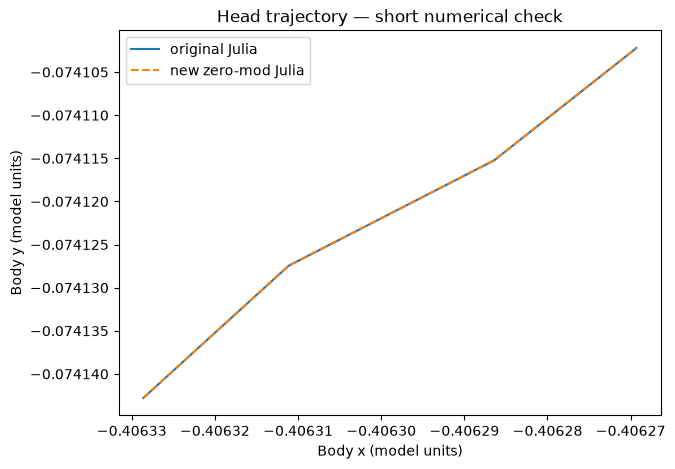

In [18]:
plt.figure(figsize=(7,5))
plt.plot(np.asarray(legacy['x_solution'])[:,0],np.asarray(legacy['y_solution'])[:,0],label='original Julia')
plt.plot(new['x_solution'][:,0],new['y_solution'][:,0], '--',label='new zero-mod Julia')
plt.legend(); plt.xlabel('Body x (model units)'); plt.ylabel('Body y (model units)'); plt.title('Head trajectory — short numerical check'); plt.show()

## Next step

After comparing errors above, increase STEPS gradually. Never infer biological roaming/dwelling from a few hundredths of a second. Keep the original neural/body parameters (including fluid viscosity) identical in both arms.

In [20]:
# =============================================================
# FOLLOW-UP DIAGNOSTIC A  —  body stability, zero input
# =============================================================
import numpy as np, traceback
SEP = "=" * 78

print(SEP); print("A1. ZERO-INPUT BODY RUN"); print(SEP)
try:
    nb, bb = make_worm(seed=10)
    zero_inputs = np.zeros((4, 279), dtype=float)   # NO external drive
    out = sim.run_network_julia(nb, bb, zero_inputs)
    for k in ("v_solution","s_solution","muscle_force","x_solution","y_solution"):
        if k in out:
            a = np.asarray(out[k], float)
            print(f"  {k:14s} shape={str(a.shape):16s} "
                  f"finite={np.isfinite(a).all()} "
                  f"nan={np.isnan(a).sum()} inf={np.isinf(a).sum()} "
                  f"max|.|={np.nanmax(np.abs(a)):.4g}")
except Exception as e:
    print("ZERO-INPUT FAILED:", type(e).__name__)
    print(str(e)[:3000])

print()
print(SEP); print("A2. TINY-INPUT BODY RUN (input * 1e-3)"); print(SEP)
try:
    nb, bb = make_worm(seed=10)
    tiny = np.asarray(PRESET[:4], float) * 1e-3
    out = sim.run_network_julia(nb, bb, tiny)
    for k in ("v_solution","s_solution","muscle_force","x_solution","y_solution"):
        if k in out:
            a = np.asarray(out[k], float)
            print(f"  {k:14s} shape={str(a.shape):16s} "
                  f"finite={np.isfinite(a).all()} "
                  f"max|.|={np.nanmax(np.abs(a)):.4g}")
except Exception as e:
    print("TINY-INPUT FAILED:", type(e).__name__)
    print(str(e)[:3000])

print()
print(SEP); print("A3. TALLER INPUT (STEPS=10, small amplitude)"); print(SEP)
try:
    nb, bb = make_worm(seed=10)
    small = np.asarray(PRESET[:10], float) * 1e-2
    out = sim.run_network_julia(nb, bb, small)
    print("  10-step small-amplitude run OK")
    for k in ("v_solution","s_solution","muscle_force","x_solution","y_solution"):
        if k in out:
            a = np.asarray(out[k], float)
            print(f"  {k:14s} finite={np.isfinite(a).all()} max|.|={np.nanmax(np.abs(a)):.4g}")
except Exception as e:
    print("SMALL-AMPLITUDE FAILED:", type(e).__name__)
    print(str(e)[:3000])

print()
print(SEP); print("A4. BODY GEOMETRY SANITY"); print(SEP)
for attr in ("body_SegCount","body_SegLength","body_Mass","body_InertiaMotion",
             "body_InertiaSeg","body_Stiff","body_StiffSeg","body_StiffMotion",
             "body_ForceTransform","body_ForceScaling","fluid_Viscosity",
             "fluid_Density","timescale","body_DragCoeff","body_CurvatureScaling",
             "body_CurvatureForcing","body_E","body_CalciumFactor"):
    if hasattr(body_a, attr):
        v = getattr(body_a, attr)
        a = np.asarray(v, float) if not isinstance(v, (int, float, bool)) else np.array([v])
        print(f"  body.{attr:24s} shape={str(a.shape):16s} "
              f"finite={np.isfinite(a).all()} "
              f"min={np.nanmin(a):+.4g} max={np.nanmax(a):+.4g}")

print()
print(SEP); print("A5. INPUT SCALE SANITY"); print(SEP)
print(f"  PRESET shape={PRESET.shape} dtype={PRESET.dtype}")
print(f"  PRESET first row  : min={PRESET[0].min():.4g} max={PRESET[0].max():.4g}")
print(f"  PRESET first col  : min={PRESET[:,0].min():.4g} max={PRESET[:,0].max():.4g}")
print(f"  any negative      : {(PRESET < 0).any()}")
print(f"  any non-finite    : {(~np.isfinite(PRESET)).any()}")

print("\nFOLLOW-UP A COMPLETE.")

A1. ZERO-INPUT BODY RUN
  v_solution     shape=(4, 279)         finite=True nan=0 inf=0 max|.|=6.395
  s_solution     shape=(4, 279)         finite=True nan=0 inf=0 max|.|=0.01859
  muscle_force   shape=(4, 48)          finite=True nan=0 inf=0 max|.|=6000
  x_solution     shape=(4, 192)         finite=True nan=0 inf=0 max|.|=19.08
  y_solution     shape=(4, 192)         finite=True nan=0 inf=0 max|.|=1.094

A2. TINY-INPUT BODY RUN (input * 1e-3)
  v_solution     shape=(4, 279)         finite=True max|.|=6.344
  s_solution     shape=(4, 279)         finite=True max|.|=0.01859
  muscle_force   shape=(4, 48)          finite=True max|.|=6000
  x_solution     shape=(4, 192)         finite=True max|.|=19.08
  y_solution     shape=(4, 192)         finite=True max|.|=1.092

A3. TALLER INPUT (STEPS=10, small amplitude)
  10-step small-amplitude run OK
  v_solution     finite=True max|.|=80.5
  s_solution     finite=True max|.|=0.04837
  muscle_force   finite=True max|.|=6000
  x_solution     fi